# Chapter 15 — Statistical Modeling with Statsmodels

Statsmodels provides interpretable statistical models with coefficient estimates, uncertainty measures, diagnostics, and formal inference. Learn linear regression, categorical predictors, residual analysis, and time-series foundations.

## Prerequisites
Pandas, NumPy, descriptive statistics, and basic probability; SciPy statistics is recommended.

## Learning goals
- Fit and interpret ordinary least squares regression.
- Use formulas and categorical variables safely.
- Interpret coefficients, confidence intervals, p-values, and model fit.
- Evaluate residual assumptions and recognize model limitations.
- Understand the introductory workflow for time-series analysis.

**Study sequence:** use the theory notebook first, then tutorial, then lab. The examples use the bundled synthetic data unless otherwise noted.

In [1]:
from pathlib import Path
ROOT=Path.cwd()
if not (ROOT/"data").exists() and (ROOT.parent/"data").exists(): ROOT=ROOT.parent
DATA=ROOT/"data"
print("Data directory:", DATA.resolve())

Data directory: /mnt/data/python_data_analysis_book/data


## Practical scenario

Build an interpretable model of revenue using units, discount, and region. Explain the reference category, coefficient units, model fit, residual diagnostics, and limits of causal interpretation.

## Tasks to complete

- Fit `revenue ~ units + discount + C(region)`.
- Interpret the units and discount coefficients with units and caveats.
- Compare conventional and HC3 standard errors.
- Make a residual-versus-fitted plot and a Q-Q plot.
- Evaluate out-of-sample prediction separately from in-sample fit.

**Working rule:** write your own code in the next cell before opening the reference solution. Explain each assumption and validate the result.

In [2]:
# TODO: complete the practical lab here.
# Start by loading the relevant dataset or defining the required input.
# Add validation checks before calculating the requested outputs.

## Worked reference solution

The following is one valid approach. It is not the only possible solution. Compare your work with it, and explain any differences in assumptions, handling, or output.

                            OLS Regression Results                            
Dep. Variable:                revenue   R-squared:                       0.177
Model:                            OLS   Adj. R-squared:                  0.159
Method:                 Least Squares   F-statistic:                     10.04
Date:                Wed, 04 Nov 2026   Prob (F-statistic):           1.02e-08
Time:                        18:19:26   Log-Likelihood:                -3331.4
No. Observations:                 240   AIC:                             6675.
Df Residuals:                     234   BIC:                             6696.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept           -1.19e+05   5.31

/mnt/data/python_data_analysis_book/Chapter_15_statistical_modeling_with_statsmodels/Chapter_15_Practical_Lab_and_Exercises.ipynb:6: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



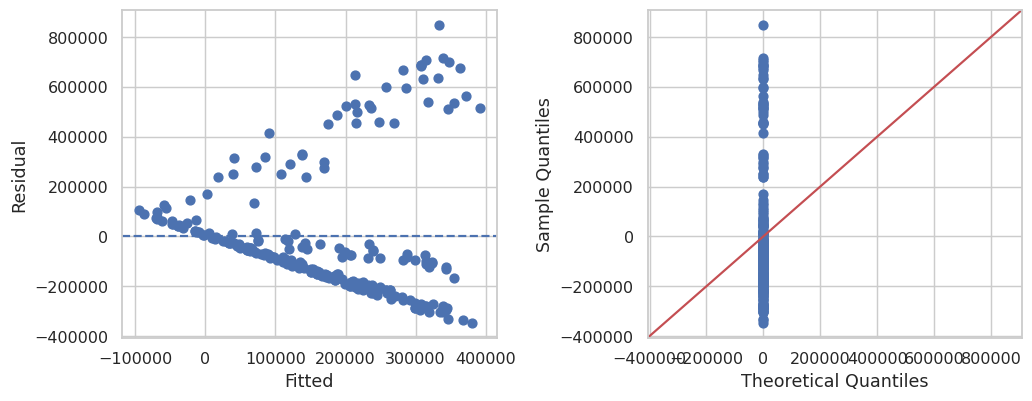

In [3]:
import pandas as pd, statsmodels.formula.api as smf, statsmodels.api as sm, matplotlib.pyplot as plt
sales=pd.read_csv(DATA/"sales.csv")
model=smf.ols("revenue ~ units + discount + C(region)",data=sales).fit()
print(model.summary()); print("HC3 standard errors:",model.get_robustcov_results(cov_type="HC3").bse)
fig,axes=plt.subplots(1,2,figsize=(10,4)); axes[0].scatter(model.fittedvalues,model.resid); axes[0].axhline(0,ls="--"); axes[0].set(xlabel="Fitted",ylabel="Residual")
sm.qqplot(model.resid,line="45",ax=axes[1]); plt.tight_layout(); plt.show()

## Extension challenge

Add a units-by-discount interaction and compare it with the main-effects model using an appropriate nested model comparison. Check collinearity and explain why model fit alone cannot establish causality.

## Further reading

- Statsmodels user guide: https://www.statsmodels.org/stable/user-guide.html
- Formula examples: https://www.statsmodels.org/stable/examples/index.html

## Completion checklist

- [ ] I can explain the topic without reading the cells.
- [ ] I can reproduce the examples from a clean kernel.
- [ ] I completed each task and checked the reference solution.
- [ ] I tested an edge case.
- [ ] I can describe at least one limitation or risk.